# Operando Pipeline Runner

Fill in the paths below, then run all cells.

This notebook loads `operando data.py` and `operando plots.py` relative to the `toolbox/operando` folder so it works regardless of where `toolbox` lives.

In [1]:
# Imports
import os
import importlib.util
from datetime import timedelta

# Resolve module paths relative to this notebook location
# Assumes this notebook lives in toolbox/operando
notebook_dir = os.path.abspath(os.getcwd())
pipeline_dir = "/data01/data_acquisition/scripts/toolbox"
data_module_path = os.path.join(pipeline_dir, "operando/operando data.py")
plots_module_path = os.path.join(pipeline_dir, "operando/operando plots.py")

# Load operando data module
data_spec = importlib.util.spec_from_file_location("operando_data", data_module_path)
operando_data = importlib.util.module_from_spec(data_spec)
data_spec.loader.exec_module(operando_data)

# Load operando plots module
plots_spec = importlib.util.spec_from_file_location("operando_plots", plots_module_path)
operando_plots = importlib.util.module_from_spec(plots_spec)
plots_spec.loader.exec_module(operando_plots)

run_operando_pipeline = operando_data.run_operando_pipeline


In [2]:
# === Base directory ===
# Set this to the root folder that contains your data_raw folder
base_dir = r"/data01/Rahul_BOA_Dec2025/nci_data"
root_dir = r"/data01/Rahul_BOA_Dec2025"
# === Paths under base_dir ===
exp_name = "exp1003_MgCoatedCEL25_asymmetric_cell3"

exp_dir = os.path.join(base_dir, exp_name)
beamhistory_path = os.path.join(base_dir, "Rahul_BOA_Dec2025_" + exp_name + '.csv')

reference_dir = os.path.join(root_dir, "Ref/exp004_Ref1um_NewCell_40x20NA_wmetal")
reference_beamhistory_path = os.path.join(root_dir, "Ref/Rahul_BOA_Dec2025_Ref.csv")
reference_bin_y = 2
reference_bin_x = 2
reference_final_subfolder = "final"


# Optional
output_dir = None  # auto-name with experiment folder
exposure_seconds = 2
uncorrected_output_folder_name = None  # auto-name with experiment folder



In [ ]:
# Run pipeline
result = run_operando_pipeline(
    exp_dir=exp_dir,
    beamhistory_path=beamhistory_path,
    output_dir=output_dir,
    exposure_seconds=exposure_seconds,
    reference_dir=reference_dir,
    reference_beamhistory_path=reference_beamhistory_path,
    uncorrected_output_folder_name=uncorrected_output_folder_name,
    reference_bin_y=reference_bin_y,
    reference_bin_x=reference_bin_x,
    reference_final_subfolder=reference_final_subfolder,
)

result


## Background Subtraction (Post-ImageJ)
 This section subtracts a background TIFF from the corrected images and writes intermediate and final outputs.


In [ ]:
from pathlib import Path
import numpy as np
import tifffile

# === Fill these in ===
# Path to background TIFF to subtract
background_path = os.path.join(base_dir, "bg_" + exp_name + ".tif")

# Input corrected folder (from pipeline)
corrected_dir = Path(result["corrected_dir"])

# Final output folder (sibling to corrected_dir)
final_dir = corrected_dir.parent / ("final_" + exp_name)
final_dir.mkdir(parents=True, exist_ok=True)

# Load background image
bg = tifffile.imread(background_path).astype(np.float32)

def read_custom_tags(path):
    try:
        with tifffile.TiffFile(path) as tif:
            tags = tif.pages[0].tags
            out = {}
            for code in (65000, 65001, 65002):
                if code in tags:
                    out[code] = tags[code].value
            return out
    except Exception:
        return {}

for p in sorted(corrected_dir.iterdir()):
    if not p.is_file():
        continue
    try:
        img = tifffile.imread(str(p)).astype(np.float32)
    except Exception:
        continue

    if img.shape != bg.shape:
        raise ValueError(f"Background shape {bg.shape} does not match image {p.name} shape {img.shape}")

    bgsub = img - bg

    # Optional: clip negatives
    bgsub = np.maximum(bgsub, 0)

    tags = read_custom_tags(str(p))
    extratags = []
    if 65001 in tags:
        extratags.append((65001, "d", 1, float(tags[65001]), False))
    if 65000 in tags:
        extratags.append((65000, "s", 0, tags[65000], False))
    if 65002 in tags:
        extratags.append((65002, "s", 0, tags[65002], False))

    final_path = final_dir / p.name
    tifffile.imwrite(str(final_path), bgsub.astype(np.float32), extratags=extratags)

print("Wrote:", final_dir)

### The images should have been OB-corrected with the reference image. Before plotting, you may need to manually filter bright spots from TPX hot pixels.

# Plotting and Video

This section loads corrected images, extracts `MeanTPXModifiedTime` from TIFF tags, loads electrochemical data, then creates:
- A potential + image video
- A potential + thickness plot

In [3]:
final_dir = os.path.join(base_dir, "final_" + exp_name)
print(final_dir)

/data01/Rahul_BOA_Dec2025/nci_data/final_exp1003_MgCoatedCEL25_asymmetric_cell3


In [15]:
# Plot/video settings
conv_thickness = 0.0485 * 5
time_column = "time/s"
fps = 10
dt_seconds = 120
cmap = "inferno"
vmin = 0
vmax = 12
dpi = 150
merge_minutes = 1
merge_method = "mean"
roi_large = dict(r0=160, x0=221, y0=222)

pixel_size=55              # Pixel size in micrometers
scalebar_length=5000       # 5000 micrometers = 5 mm
scale_label="5 mm"         # Label to display
cbar_label="Li thickness"
cbar_n_ticks = 4
scalebar_color='white'     # White scale bar (visible on dark images)
scale_fontsize=16          # Font size
scalebar_width_frac=0.02   # Height of scale bar
scalebar_position='lower left'  # Position
scalebar_margin=0.05        # Margin from edge

potential_ylim=(-0.4, 0.6)

echem_folder = os.path.join(root_dir, "echem_data")
video_output_path = os.path.join(base_dir, exp_name + '.mp4')

In [16]:
import tifffile
from datetime import datetime

def load_corrected_images_with_time(corrected_dir, tag_id=65002, r0=None, x0=None, y0=None):
    records = []
    for fname in sorted(os.listdir(corrected_dir)):
        path = os.path.join(corrected_dir, fname)
        if not os.path.isfile(path):
            continue
        # Try to open as TIFF (works even if no extension)
        try:
            with tifffile.TiffFile(path) as tif:
                img = tif.asarray()
                if r0 is not None and x0 is not None and y0 is not None:
                    y_start = max(0, y0 - r0)
                    y_end = min(img.shape[0], y0 + r0)
                    x_start = max(0, x0 - r0)
                    x_end = min(img.shape[1], x0 + r0)
                    img = img[y_start:y_end, x_start:x_end]
                tags = tif.pages[0].tags
                if tag_id not in tags:
                    continue
                dt_str = tags[tag_id].value
        except Exception:
            continue

        # Parse datetime
        try:
            dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S")
        except Exception:
            continue

        records.append((dt, img, path))

    records.sort(key=lambda x: x[0])
    img_datetimes = [r[0] for r in records]
    img_series = [r[1] for r in records]
    paths = [r[2] for r in records]
    return img_datetimes, img_series, paths

In [17]:
# Load final images (MeanTPXModifiedTime)
img_datetimes, img_series, img_paths = load_corrected_images_with_time(
    final_dir,
    tag_id=65002,
    r0=roi_large["r0"],
    x0=roi_large["x0"],
    y0=roi_large["y0"],
)

# Convert to natural Li thickness
img_series = [img / conv_thickness for img in img_series]

# Load electrochemical data
echem_datetimes, potential_series, echem_thickness_series = operando_plots.load_echem_data(
    echem_folder,
    conv_thickness=conv_thickness,
    time_column=time_column,
)

# Optionally merge images in time
img_datetimes, img_series = operando_plots.merge_images_by_time(
    img_datetimes, img_series, merge_minutes=merge_minutes, method=merge_method
)


In [18]:
###### Make potential + image video
operando_plots.make_potential_image_video_uniform_time(
    echem_datetimes=echem_datetimes,
    potential_series=potential_series,
    img_datetimes=img_datetimes,
    img_series=img_series,
    output_path=video_output_path,
    fps=fps,
    dt_seconds=dt_seconds,
    dpi=dpi,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    potential_ylim=potential_ylim,
    pixel_size=pixel_size,              # Pixel size in micrometers
    scalebar_length=scalebar_length,       # 5000 micrometers = 5 mm
    scale_label=scale_label,         # Label to display
    cbar_label=cbar_label,
    cbar_n_ticks = cbar_n_ticks,
    scalebar_color=scalebar_color,     # White scale bar (visible on dark images)
    scale_fontsize=scale_fontsize,          # Font size
    scalebar_width_frac=scalebar_width_frac,   # Height of scale bar
    scalebar_position=scalebar_position,  # Position
    scalebar_margin=scalebar_margin        # Margin from edge
)

## Capacity Events -> Neutron Image Indices
 Find capacity turning points/zeros, locate nearest neutron images, then plot them.


In [19]:
# -----------------------------
# Custom single-pass cell: turning points + nth image + last event
# -----------------------------
import os
from datetime import timedelta
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Inputs / defaults
# -----------------------------
exclude_indices = [6]  # 0-based indices in event list to exclude
label_start = globals().get("label_start", 0)

# Set this to choose which neutron image should replace the "first image" event
nth_image_index = 0  # Example: 0-based index of neutron image

events = []
img_indices = np.array([], dtype=int)
event_times_for_plot = []

# -----------------------------
# Sanity check
# -----------------------------
if len(img_datetimes) == 0:
    raise ValueError("No image timestamps found. Check corrected image metadata.")

# -----------------------------
# Turning points from capacity
# -----------------------------
cap_pairs = [
    (t, c)
    for t, c in zip(echem_datetimes, echem_thickness_series / conv_thickness)
    if img_datetimes[0] <= t <= img_datetimes[-1]
]

if len(cap_pairs) == 0:
    print("No capacity data within image time range.")
else:
    cap_times = [t for t, _ in cap_pairs]
    cap_values = [c for _, c in cap_pairs]

    events = operando_data.find_capacity_turning_points(
        cap_times,
        cap_values,
    )

# -----------------------------
# Build img_indices for events
# -----------------------------
if events:
    event_times = [e["time"] for e in events]
    img_indices = np.asarray(
        operando_data.find_nearest_image_indices(event_times, img_datetimes),
        dtype=int,
    )

# -----------------------------
# Replace first neutron image event
# -----------------------------
if 0 <= nth_image_index < len(img_datetimes):
    img_indices = np.insert(img_indices, 0, nth_image_index)
else:
    print(f"nth_image_index={nth_image_index} is out of bounds, skipping replacement of first image.")

# -----------------------------
# Always include last event: pick earlier of last EC point or last neutron image
# -----------------------------
last_event_dt = min(echem_datetimes[-1], img_datetimes[-1])
# Find index of nearest image to last_event_dt
last_idx = np.argmin([abs((t - last_event_dt).total_seconds()) for t in img_datetimes])

# Append last event if not already included
if img_indices.size == 0 or img_indices[-1] != last_idx:
    img_indices = np.append(img_indices, last_idx)

# -----------------------------
# Event times for plotting (slightly offset for aesthetics)
# -----------------------------
event_times_for_plot = [img_datetimes[idx] - timedelta(minutes=2.5) for idx in img_indices]

# -----------------------------
# Debug output
# -----------------------------
for e, idx in zip(events, img_indices[:len(events)]):
    print(f"{e['time']} {e['labels']} -> image index {idx}")
print(f"nth image ({nth_image_index}) -> image index {nth_image_index}")
print(f"last event -> image index {last_idx}, datetime {img_datetimes[last_idx]}")


2025-12-07 23:04:44 ['turning'] -> image index 0
2025-12-07 23:04:44 ['turning'] -> image index 14
2025-12-07 23:27:44 ['turning'] -> image index 19
2025-12-07 23:27:52 ['turning'] -> image index 31
2025-12-07 23:27:52 ['turning'] -> image index 42
2025-12-07 23:28:02 ['turning'] -> image index 54
2025-12-08 00:27:52 ['turning'] -> image index 65
2025-12-08 00:27:52 ['turning'] -> image index 66
2025-12-08 01:22:09 ['turning'] -> image index 77
2025-12-08 01:22:09 ['turning'] -> image index 89
2025-12-08 02:22:09 ['turning'] -> image index 101
2025-12-08 02:22:09 ['turning'] -> image index 113
nth image (0) -> image index 0
last event -> image index 113, datetime 2025-12-08 07:18:19


In [20]:
# -----------------------------
# Thickness from images (ROI)
# -----------------------------
roi_small = dict(r0=111, x0=221, y0=222)
avg_thickness_series = operando_plots.circular_average_thickness_series(img_series, **roi_small)

# Convert to natural Li thickness
avg_thickness_series = avg_thickness_series / conv_thickness

# -----------------------------
# Apply exclude list (single source of truth)
# -----------------------------
filtered_event_times = []
filtered_event_indices = []
filtered_image_indices = []

for i, (evt_t, idx) in enumerate(zip(event_times_for_plot, img_indices)):
    if i not in exclude_indices:
        filtered_event_times.append(evt_t)
        filtered_event_indices.append(i)
        filtered_image_indices.append(int(idx))

print(f"Kept event indices (in event list): {filtered_event_indices}")
print(f"Corresponding FULL image indices: {filtered_image_indices}")

Kept event indices (in event list): [0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11]
Corresponding FULL image indices: [0, 14, 19, 31, 42, 54, 66, 77, 89, 101, 113]


In [21]:
# -----------------------------
# Export thickness values txt
# -----------------------------
out_text_path = os.path.join(base_dir, "thickness_values.txt")

def print_and_save(message, fh):
    print(message)
    fh.write(message + "\n")

with open(out_text_path, "w") as f:
    print_and_save("\n" + "=" * 60, f)
    print_and_save("AVERAGE THICKNESS AT SELECTED EVENTS", f)
    print_and_save("=" * 60, f)

    thickness_values = []
    for i, (event_time, img_idx) in enumerate(zip(filtered_event_times, filtered_image_indices)):
        thickness_value = avg_thickness_series[img_idx]
        thickness_values.append(thickness_value)

        event_label = chr(97 + int(label_start) + i)
        event_time_str = event_time.strftime("%Y-%m-%d %H:%M:%S")
        closest_time_str = img_datetimes[img_idx].strftime("%Y-%m-%d %H:%M:%S")
        time_diff_seconds = abs((img_datetimes[img_idx] - event_time).total_seconds())

        print_and_save(f"Event {event_label}:", f)
        print_and_save(f"  Event time:      {event_time_str}", f)
        print_and_save(f"  Closest image:   {closest_time_str}", f)
        print_and_save(f"  Time difference: {time_diff_seconds:.1f} seconds", f)
        print_and_save(f"  Avg thickness:   {thickness_value:.4f}", f)
        print_and_save(f"  Image index:     {img_idx}", f)
        print_and_save("", f)

    print_and_save("-" * 60, f)
    print_and_save("SUMMARY:", f)
    print_and_save(f"  ROI: center=({roi_small['x0']}, {roi_small['y0']}), radius={roi_small['r0']} pixels", f)
    print_and_save(f"  Total original events: {len(event_times_for_plot)}", f)
    print_and_save(f"  Excluded indices: {exclude_indices}", f)
    print_and_save(f"  Number of kept events: {len(filtered_event_times)}", f)
    if thickness_values:
        print_and_save(f"  Thickness range:  {np.min(thickness_values):.4f} to {np.max(thickness_values):.4f}", f)
        print_and_save(f"  Mean thickness:   {np.mean(thickness_values):.4f}", f)
        print_and_save(f"  Std thickness:    {np.std(thickness_values):.4f}", f)
    print_and_save("=" * 60 + "\n", f)

print(f"Text output saved to: {out_text_path}")


AVERAGE THICKNESS AT SELECTED EVENTS
Event a:
  Event time:      2025-12-07 21:49:42
  Closest image:   2025-12-07 21:52:12
  Time difference: 150.0 seconds
  Avg thickness:   0.0000
  Image index:     0

Event b:
  Event time:      2025-12-07 22:59:50
  Closest image:   2025-12-07 23:02:20
  Time difference: 150.0 seconds
  Avg thickness:   8.0141
  Image index:     14

Event c:
  Event time:      2025-12-07 23:24:53
  Closest image:   2025-12-07 23:27:23
  Time difference: 150.0 seconds
  Avg thickness:   6.1916
  Image index:     19

Event d:
  Event time:      2025-12-08 00:25:00
  Closest image:   2025-12-08 00:27:30
  Time difference: 150.0 seconds
  Avg thickness:   11.0024
  Image index:     31

Event e:
  Event time:      2025-12-08 01:20:07
  Closest image:   2025-12-08 01:22:37
  Time difference: 150.0 seconds
  Avg thickness:   6.1184
  Image index:     42

Event f:
  Event time:      2025-12-08 02:20:14
  Closest image:   2025-12-08 02:22:44
  Time difference: 150.0 secon

Image saved to: /data01/Rahul_BOA_Dec2025/nci_data/potential_exp1003_MgCoatedCEL25_asymmetric_cell3.png


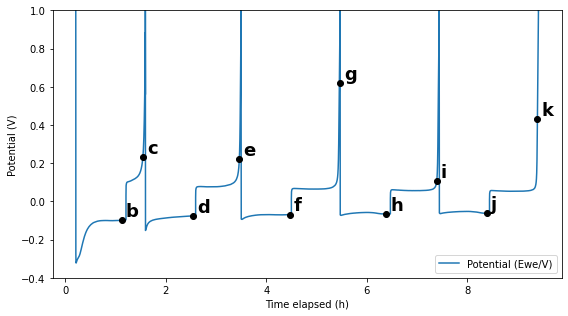

In [22]:
# -----------------------------
# Plot + save PNG
# -----------------------------
fig = operando_plots.plot_potential_and_thickness(
    echem_datetime_series=echem_datetimes,
    potential_series=potential_series,
    echem_thickness_series=echem_thickness_series,
    img_datetime_series=img_datetimes,
    avg_thickness_series=avg_thickness_series,
    potential_ylim=potential_ylim,
    event_times=filtered_event_times,
    label_start=0,
    event_marker_size=6,
    event_label_fontsize=18,
    show=False,  # requires updated function signature
)

out_path = os.path.join(base_dir, "potential_" + exp_name+".png")
os.makedirs(os.path.dirname(out_path), exist_ok=True)
fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"Image saved to: {out_path}")

plt.show()

Saved: /data01/Rahul_BOA_Dec2025/nci_data/nci_exp1003_MgCoatedCEL25_asymmetric_cell3.png


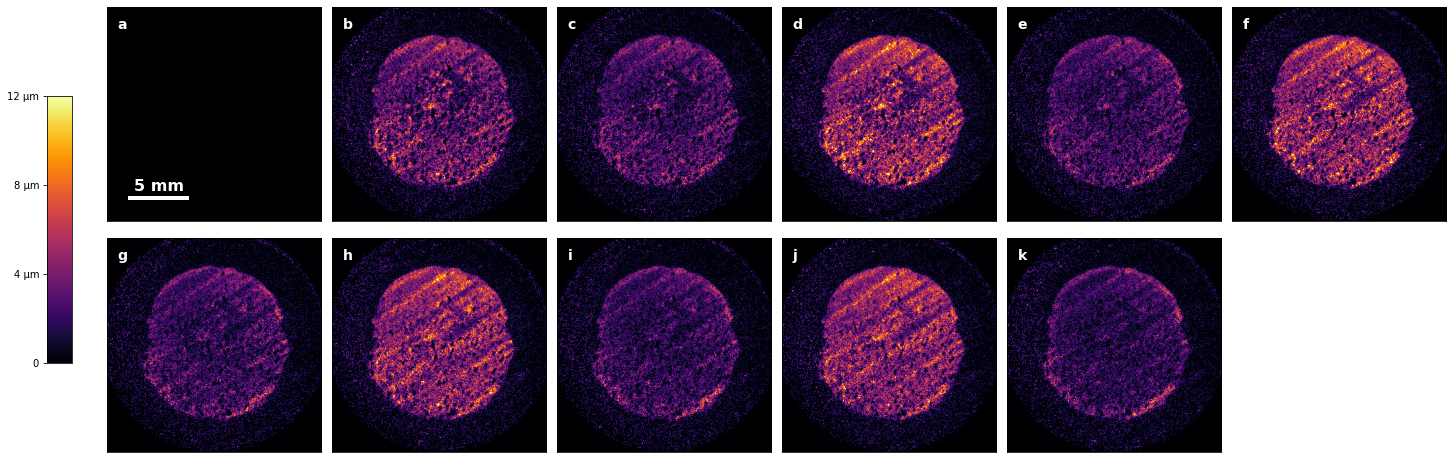

In [23]:
# Plot images at these indices
plots_path = os.path.join(os.path.join(pipeline_dir, "plots", "plots.py"))
plots_spec = importlib.util.spec_from_file_location("plots_mod", plots_path)
plots_mod = importlib.util.module_from_spec(plots_spec)
plots_spec.loader.exec_module(plots_mod)

fig, axes = plots_mod.plot_images(
    img_series=img_series,
    img_indices=filtered_image_indices,
    pixel_size=pixel_size,
    show_labels=True,

    # Color bar
    cmap="inferno",
    cbar_ranges=[(vmin, vmax)],
    cbar_shared_length=0.6,
    cbar_mode="shared left",
    cbar_fontsize=16,
    cbar_unit=["μm"],
    cbar_width_frac=0.015,
    cbar_show_ticklines=True,
    cbar_n_ticks=cbar_n_ticks,
    cbar_pad=0.02,

    # Scale bar
    scale_fontsize=16,
    scalebar_mode="inside",
    scalebar_length=5000,
    scale_label="5 mm",
    scalebar_width_frac=0.02,

    # Figure layout
    spacing=(0.05, 0),
    figsize=(24, 8.5),
    ncols=6,
    nrows=2,
)


# Save figure safely
out_path = os.path.join(base_dir, "nci_" + exp_name + ".png")
os.makedirs(os.path.dirname(out_path), exist_ok=True)
fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"Saved: {out_path}")